# Evaluar la propuesta computacional

Nivel 4. Requisitos previos: las tres lecciones anteriores y una exportación experimental completa. Tiempo de lectura: 40 minutos.

**Pregunta:** ¿La formulación original menor de la proyección asimétrica cumple el criterio temporal registrado frente a la referencia equivalente más rápida en entradas reservadas?


## Objetivos

Una propuesta computacional debe resistir una comparación capaz de rechazarla. El candidato cambia la operación proximal por lado y conserva el sistema principal OSQP en la dimensión original. La observación estructural motiva una hipótesis de ingeniería, pero no demuestra mejora temporal. Validación, preparación densa, iteraciones y madurez pueden contradecir un argumento basado únicamente en dimensiones.

Ejecutaremos métodos en un problema de desarrollo, examinaremos KKT original y condicionamiento y recalcularemos el resultado reservado. Las semillas se registraron antes de generar datos. El cuaderno no elige un subconjunto favorable ni reajusta el candidato al mirar resultados. Su conclusión distingue una medición de implementación acotada de novedad matemática, adopción práctica y aceptación de publicación.


## Preparación

Utilice un entorno separado de Python 3.12. El motor nativo es una distribución separada. Instale el entorno exacto fuera del cuaderno:

```bash
pip install "softqp==0.1.0"
pip install "numpy==2.5.4"
pip install "scipy==1.18.1"
pip install "matplotlib==3.11.2"
pip install "osqp==1.1.3"
pip install "daqp==0.10.3"
pip install "elastiqp==0.2.0"
```

La única celda de preparación localiza el repositorio, importa los métodos e imprime versiones numéricas. No se instala software dentro del kernel.


In [1]:
# Localizar entradas una vez deja las celdas científicas dedicadas a optimización.
from pathlib import Path
import sys
import json
import importlib.metadata
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from softqp.solvers import solve
from softqp.flex import solve_flex
from softqp.elasti import solve_elastiqp
from softqp.sessions import PreparedSolver
candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.softqp_cases import scalar, mpc
from pipeline.softqp_campaign import generated_problem, primary_endpoint
from pipeline.optimality import kkt
from pipeline.control import predict_states
for distribution in ("softqp", "numpy", "scipy", "matplotlib", "osqp", "daqp", "elastiqp"):
    print(distribution, importlib.metadata.version(distribution))
accurate = dict(eps_abs=1e-9, eps_rel=1e-9, adaptive_rho_interval=25)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})

# Los identificadores del solver se conservan; las figuras usan nombres en español.
method_labels = {
    'lifted': 'Holguras explícitas',
    'generalized': 'Proyección generalizada',
    'asymmetric': 'Proyección asimétrica',
    'daqp': 'DAQP',
    'flex': 'FlexQP',
    'elastiqp': 'ElastiQP',
}


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Datos

El ejemplo ejecutable usa semilla 1000, n=32, densidad 0.05, condición uno y costos elásticos asimétricos. La campaña abarca por separado seis semillas reservadas, n=32/64/128/256, dos densidades, dos condiciones y tres familias. Siete repeticiones medidas siguen a un calentamiento por backend e instancia. El orden se aleatoriza dentro de cada repetición pareada.

Leemos una vez todas las observaciones JSONL. Se conservan calentamientos, incompatibilidades, fallas y límites de recursos. La función aplica el filtro registrado: el cuaderno no elimina filas antes de entregárselas. El verificador de exportación comprueba inventario y hashes independientemente de esta lección.


In [2]:
# Conservar el denominador completo antes de aplicar el resultado registrado.
campaign = json.loads((root / "data/derived/experiments/campaign.json").read_text(encoding="utf-8"))
trial_file = root / "data/derived/experiments/trials.jsonl"
trials = [json.loads(line) for line in trial_file.read_text(encoding="utf-8").splitlines()]
protocol = campaign["protocol"]
print("Semillas reservadas:", protocol["seeds"]["heldout"])
print("Observaciones originales con calentamientos:", len(trials))


Semillas reservadas: [9000, 9001, 9002, 9003, 9004, 9005]
Observaciones originales con calentamientos: 21888


## Método

Comenzamos con una solución real a escala de desarrollo. La extensión admite precios lineales/cuadráticos no negativos por lado y máscara dura fija. La actualización proximal escalar surge de minimizar la penalización convexa del intervalo. El sistema ADMM sigue acoplando variables: la contracción por fila no descompone todo el QP en decisiones independientes. Adaptar rho puede exigir refactorización; conservar dimensiones no promete una única factorización permanente.

Usamos iguales tolerancias absolutas y relativas en estas llamadas. Las soluciones educativas examinan corrección; sus tiempos nuevos no reemplazan las mediciones prerregistradas.


In [3]:
# Esta instancia de desarrollo es distinta de toda semilla reservada.
spec = dict(n=32, density=0.05, seed=1000, family="asymmetric-elastic", condition=1)
problem = generated_problem(spec)
settings = dict(eps_abs=1e-8, eps_rel=1e-8, max_iter=200000)
native_settings = dict(settings, adaptive_rho_interval=25)
candidate = solve(problem, "asymmetric", **native_settings)
print("Dimensiones del candidato:", candidate["dimensions"])
print(f"Objetivo de desarrollo: {candidate['metrics']['objective']:.8f}")


Dimensiones del candidato: {'variables': 32, 'rows': 64, 'nnz': 144}
Objetivo de desarrollo: -84.75011385


Una referencia explícita justa utiliza la formulación compacta cuando hay simetría. Este ejemplo asimétrico exige holguras distintas por lado finito. El oráculo independiente usa OSQP estándar y las holguras temporizadas de la campaña usan el mismo fork nativo del candidato. Así no se confunde una diferencia entre compilaciones con una ventaja de formulación.


In [4]:
# Usar una implementación estándar independiente como oráculo de corrección.
lifted = solve(problem, "lifted", reference_backend="stock", **native_settings)
relative_gap = abs(candidate["metrics"]["objective"] - lifted["metrics"]["objective"])
relative_gap /= max(1.0, abs(lifted["metrics"]["objective"]))
reduction = 1 - candidate["dimensions"]["variables"] / lifted["dimensions"]["variables"]
print("Dimensiones explícitas:", lifted["dimensions"])
print(f"Reducción de dimensión primal: {100 * reduction:.6f}%")
print(f"Brecha normalizada de desarrollo: {relative_gap:.3e}")


Dimensiones explícitas: {'variables': 136, 'rows': 220, 'nnz': 547}
Reducción de dimensión primal: 76.470588%
Brecha normalizada de desarrollo: 4.599e-10


DAQP es una referencia necesaria porque ya ofrece costos blandos por lado. El candidato no puede atribuirse una capacidad nueva solo por admitir precios desiguales. Por eso el resultado registrado compara con la observación pareada más rápida entre DAQP y holguras nativas, no con la referencia más lenta. Ejecutamos DAQP para examinar el mismo objetivo mediante otro algoritmo.


In [5]:
# Un algoritmo previo por lado impide basar la novedad solo en la asimetría.
daqp = solve(problem, "daqp", **native_settings)
print("Dimensiones DAQP:", daqp["dimensions"])
print(f"Diferencia objetivo DAQP: {abs(daqp['metrics']['objective'] - lifted['metrics']['objective']):.3e}")


Dimensiones DAQP: {'variables': 32, 'rows': 64, 'nnz': 144}
Diferencia objetivo DAQP: 3.492e-09


Auditamos vectores primales y duales recuperados, además de costos. Para un problema convexo, estacionariedad, pertenencia al subgradiente de intervalo y factibilidad dura caracterizan optimalidad bajo los supuestos pertinentes. El defecto proximal examina los quiebres sin elegir una derivada arbitraria. Así se detecta mejor un punto falsamente estacionario que comparando solo objetivos.


In [6]:
# El dual debe corresponder a la penalización y no solo cancelar un gradiente.
for result in [candidate, lifted, daqp]:
    audit = kkt(problem, result["x"], result["y"])
    print(result["method"], f"estacionariedad {audit['normalized_stationarity']:.3e}",
          f"proximal {audit['normalized_proximal_defect']:.3e}",
          f"duro {audit['hard_violation']:.3e}")


asymmetric estacionariedad 8.255e-10 proximal 9.106e-09 duro 6.574e-10
lifted estacionariedad 6.609e-10 proximal 5.637e-10 duro 3.051e-11
daqp estacionariedad 9.720e-17 proximal 1.887e-15 duro 1.554e-15


## Comparación

Graficamos tamaños después de verificar semántica equivalente. DAQP también evita la expansión explícita de holguras. Por ello, una ventaja de dimensión frente a esa formulación no establece superioridad frente a la referencia más fuerte. El resultado principal utiliza la más rápida de ambas en cada observación pareada.


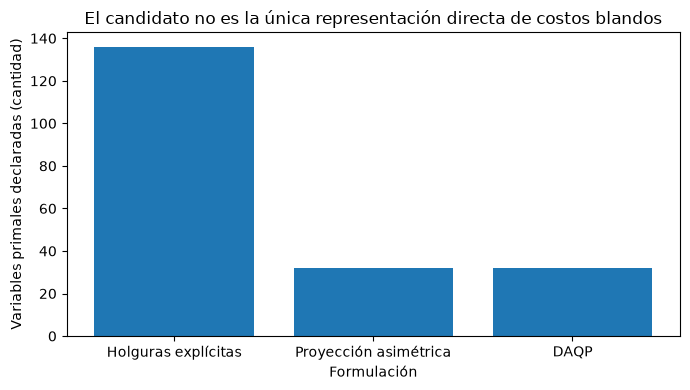

In [7]:
# Declarar dimensiones sin traducirlas en tiempos de factorización inventados.
results = [lifted, candidate, daqp]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([method_labels[r["method"]] for r in results], [r["dimensions"]["variables"] for r in results])
ax.set(xlabel="Formulación", ylabel="Variables primales declaradas (cantidad)",
       title="El candidato no es la única representación directa de costos blandos")
fig.tight_layout()
plt.show()


La formulación explícita tiene más variables porque representa cada lado con cantidades auxiliares. Ambos métodos directos evitan esa expansión particular. Las barras no muestran trabajo iterativo, condicionamiento, validación Python ni preparación del conjunto activo. La figura motiva una prueba computacional sin resolverla y evita atribuir al candidato una capacidad que ya existe en una referencia publicada.


Aumentamos solo la condición diagonal del ejemplo de desarrollo. El generador conserva filas, objetivo lineal, límites y precios dentro de la semilla. Concordar con condición uno no garantiza comportamiento a un millón, especialmente al interactuar escala y tolerancias. Esta llamada ilustra la pregunta controlada; el barrido completo conserva sus fallas separadas del estadístico temporal principal.


In [8]:
# Mantener A, q y precios al exigir mayor condicionamiento del objetivo.
difficult = generated_problem(dict(spec, condition=1000000))
difficult_native = solve(difficult, "asymmetric", **native_settings)
difficult_lift = solve(difficult, "lifted", **native_settings)
condition_gap = abs(difficult_native["metrics"]["objective"] - difficult_lift["metrics"]["objective"])
print(f"Diferencia objetivo con condición un millón: {condition_gap:.3e}")
print(f"Error duro con condición un millón: {difficult_native['metrics']['hard_violation']:.3e}")


Diferencia objetivo con condición un millón: 1.880e-08
Error duro con condición un millón: 1.110e-16


## Evidencia

La población principal es elástica asimétrica, con n al menos 128 y densidad 0.05. En cada instancia y repetición, la reducción es uno menos tiempo del candidato dividido por la referencia equivalente más rápida. Un valor negativo indica ejecución más lenta. El criterio exige mediana de al menos 10%, límite inferior del intervalo bilateral del 95% sobre cero y ningún par fallido. Se remuestrean semillas completas, no repeticiones tratadas como experimentos independientes.

Recalculamos mediante el método de análisis todas las observaciones. Los pares ausentes o rechazados permanecen en el denominador. Importación, generación y exportación quedan fuera; validación, formulación, preparación, solución y evaluación original quedan dentro. No se instrumentó factorización aislada y no puede reconstruirse restando relojes de distinto alcance.


In [9]:
# Recalcular el estadístico registrado sin seleccionar un subconjunto favorable.
endpoint = primary_endpoint(trials, protocol)
print("Criterio registrado:", endpoint["state"])
print("Pares aceptados / rechazados:", endpoint["paired_samples"], endpoint["rejected_pairs"])
print("Grupos de semilla:", endpoint["seed_clusters"])
if endpoint["median_relative_reduction"] is None:
    raise ValueError("Se requiere evidencia experimental reservada completa")
print(f"Reducción relativa mediana: {100 * endpoint['median_relative_reduction']:.3f}%")
print("Intervalo del 95% (%):", [round(100 * x, 3) for x in endpoint["confidence_interval_95"]])


Criterio registrado: not-established
Pares aceptados / rechazados: 168 0
Grupos de semilla: 6
Reducción relativa mediana: 0.500%
Intervalo del 95% (%): [-3.292, 3.945]


Mostramos efecto e intervalo por semilla junto con cero y la meta práctica. Cruzar cero indica incertidumbre de dirección bajo este remuestreo; no alcanzar el 10% es una cuestión distinta. Una estimación puntual positiva no basta. El gráfico conserva explícitamente el signo para evitar presentar un candidato más lento como mejora invirtiendo el eje.


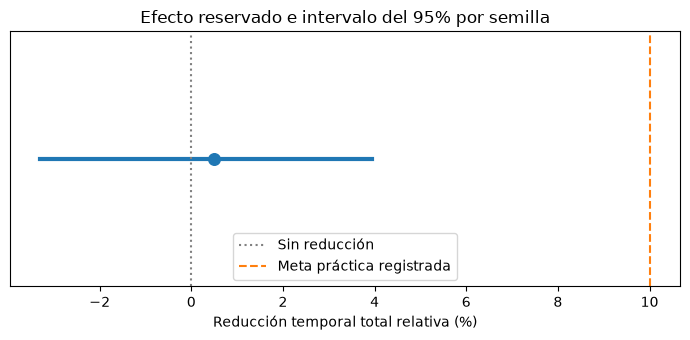

In [10]:
# El intervalo describe seis semillas en este régimen de implementación registrado.
estimate = 100 * endpoint["median_relative_reduction"]
low, high = [100 * x for x in endpoint["confidence_interval_95"]]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([low, high], [0, 0], linewidth=3)
ax.scatter([estimate], [0], s=70)
ax.axvline(0, color="gray", linestyle=":", label="Sin reducción")
ax.axvline(10, color="C1", linestyle="--", label="Meta práctica registrada")
ax.set(xlabel="Reducción temporal total relativa (%)", yticks=[],
       title="Efecto reservado e intervalo del 95% por semilla")
ax.legend()
fig.tight_layout()
plt.show()


El intervalo refleja observaciones pareadas y variación entre semillas registradas en un entorno numérico. No cubre todo modelo, equipo, hessiana ni implementación. La referencia más fuerte y la meta práctica se eligieron antes de generar la evaluación: el resultado mantiene su significado aunque sea desfavorable. Novedad algorítmica global, revisión matemática independiente y aceptación del producto desplegado son conclusiones distintas que este intervalo no establece.


## Resultados

**Respuesta:** El candidato no cumple el criterio registrado: reducción relativa mediana 0.500%, intervalo del 95% por semilla [-3.292%, 3.945%], 168 pares aceptados y 0 rechazados. Es un resultado de implementación acotado, no prueba de novedad global ni seguridad operacional.

En el ejemplo ejecutado, el candidato usa 32 variables frente a 136 de las holguras explícitas: reducción de dimensión primal declarada de 76.470588%. La representación directa de DAQP muestra por qué ese conteo no es un resultado comparativo de investigación por sí solo. La conclusión usa el alcance temporal registrado y conserva la aceptación numérica, no la apariencia favorable de una gráfica de tamaños.


## Resumen

Separe derivación, propiedad de implementación y mejora empírica. La fórmula proximal puede ser correcta aunque falle una meta; una meta puede mejorar sin establecer una idea matemática nueva. Conserve resultados negativos, limite todo éxito al régimen medido y obtenga revisión independiente antes de la promoción científica. Adoptar el motor exige cargas representativas, validación de plataforma y una política dura/blanda justificada.


## Referencias

- [Proyecciones generalizadas](https://arxiv.org/abs/2610.35631).
- [Restricciones blandas por lado en DAQP](https://darnstrom.github.io/daqp/start/advanced/soft).
- [Solver y condiciones de terminación OSQP](https://osqp.org/docs/solver/).
- Protocolo fijo: `docs/design/experiments-v1.json`; observaciones originales y manifiesto en `data/derived/experiments/`.
